<a href="https://colab.research.google.com/github/Narasimha440/Unsupervised_learning/blob/main/kmeans_agglomerativ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/mall.csv")

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [28]:
scaler = StandardScaler()
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
X_scaled = scaler.fit_transform(X)
K_range = range(2, 11)
silhouette_scores = []
agg_scores = []

In [29]:
for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42)
  cluster_labels = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, cluster_labels)
  print("Silhouette Score:", score)
  silhouette_scores.append(score)

  agg = AgglomerativeClustering(n_clusters=k)
  cluster_labels = agg.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, cluster_labels)
  print("Silhouette Score:", score)
  agg_scores.append(score)

Silhouette Score: 0.3973270007887498
Silhouette Score: 0.3842337621772661
Silhouette Score: 0.46658474419000145
Silhouette Score: 0.4610481446570447
Silhouette Score: 0.49434988482196784
Silhouette Score: 0.4925507715349343
Silhouette Score: 0.5546571631111091
Silhouette Score: 0.5538089226688662
Silhouette Score: 0.5138257534676561
Silhouette Score: 0.5386761871036926
Silhouette Score: 0.50200146805547
Silhouette Score: 0.5197949293475768
Silhouette Score: 0.4550112502601921
Silhouette Score: 0.4308617778221774
Silhouette Score: 0.4566624374485964
Silhouette Score: 0.43768997758154127
Silhouette Score: 0.44475993501732874
Silhouette Score: 0.4339007174968657


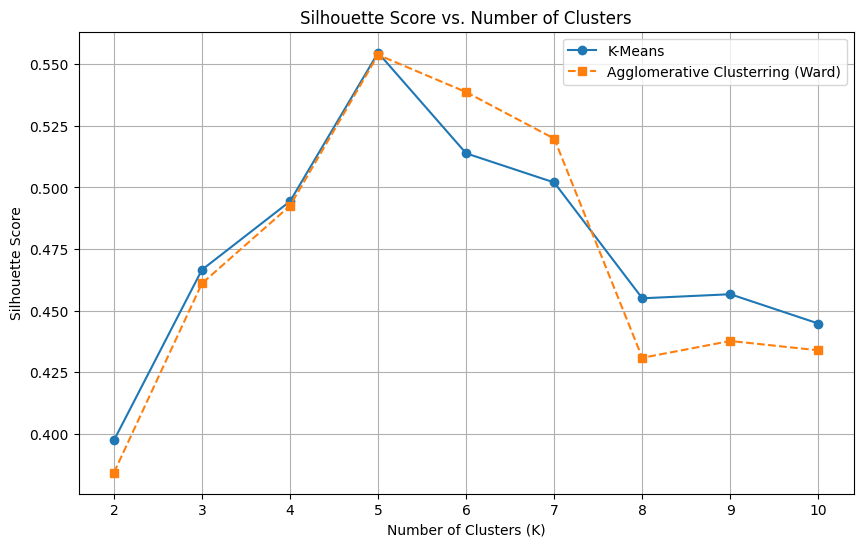

In [32]:
plt.figure(figsize=(10, 6))
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', label='K-Means')
plt.plot(K_range, agg_scores, marker='s', linestyle = '--', label='Agglomerative Clusterring (Ward)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.legend()
plt.grid(True)
plt.show()